# Project 1 — cross-validation & ROPE comparison

**3 representations × 3 models**, all on the same 50k subsample of SNLI's training split and the same 5 folds:

| | log-linear | MLPSimple | MLPNLI |
|---|---|---|---|
| Token indicator | `ti_loglin` | `ti_mlpsimple` | `ti_mlpnli` |
| Bag-of-words | `bow_loglin` | `bow_mlpsimple` | `bow_mlpnli` |
| MPNet sentence embeddings | `mpnet_loglin` | `mpnet_mlpsimple` | `mpnet_mlpnli` |

**What is used where**

| Step | Code | File |
|---|---|---|
| Data (drops label -1) | `load_snli_dataset`, `convert_to_dataframe` | `dataset.py` |
| BPE tokenizer | `train_tokenizer` | `tokenizer.py` |
| Representations | `TokenIndicator`, `BagofWords`, `MPNetEncoder` | `encoders.py` |
| Premise + hypothesis → one vector | `PairEncoder` → `[premise ; hypothesis (; overlap)]` | `encoders.py` |
| Encoder → sparse matrix in chunks | `encode_sparse` | `loglin.py` |
| Log-linear | `LogisticRegression(solver="saga")`, the model `loglin.fit` trains | scikit-learn |
| MLPSimple: `[u ; v]` → 1 hidden layer (tutorial MLP, tutorial settings) | `VectorMLPSimple` | `models.py` |
| MLPNLI: `[u, v, \|u−v\|, u·v]` → 2 hidden layers | `VectorMLPNLI` | `models.py` |
| Folds grouped by premise | `GroupKFold` | scikit-learn |
| ROPE | `BenavoliCorrelatedT` (baycomp) | `eval.py` |

Written in this notebook: the tuning / CV / training loops and the charts.

**Protocol**: (1) choose settings on SNLI's official validation split, (2) 5-fold CV with those settings, (3) ROPE comparison of the CV scores, (4) best system trained on the full training split, evaluated **once** on the test split.

## Setup

In [ ]:
import warnings
warnings.filterwarnings("ignore")   

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score
from sentence_transformers import SentenceTransformer

from dataset import load_snli_dataset, convert_to_dataframe
from tokenizer import train_tokenizer
from encoders import TokenIndicator, BagofWords, MPNetEncoder, PairEncoder
from loglin import encode_sparse
from models import VectorMLPSimple, VectorMLPNLI
from eval import BenavoliCorrelatedT

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

device: mps


In [ ]:
# settings
SUBSAMPLE = 50_000                 # pairs used for tuning + CV
K = 5                              # folds
SEED = 42
VOCAB_SIZES = [1000, 5000, 10000]  # BPE vocab size, tuned per system (token representations)
OVERLAPS = [False, True]           # PairEncoder overlap block, tuned per system (not for MLPNLI: u*v already covers it)
MAX_EPOCHS = 20                    # MLP epochs tuned in 1..MAX_EPOCHS
ROPE = 0.01                        # region of practical equivalence (accuracy points)

# training settings per MLP
TRAIN_ARGS = {
    "mlpsimple": dict(dropout=0.1, lr=1e-4, weight_decay=1e-4, batch_size=64, clip=None),
    "mlpnli": dict(dropout=0.3, lr=3e-4, weight_decay=1e-6, batch_size=128, clip=1.0),
}

ST_MODEL = "sentence-transformers/nli-mpnet-base-v2"   # the model MPNetEncoder wraps (NB: fine-tuned on SNLI + MultiNLI)

REPS = ["indicator", "bow", "mpnet"]
SHORT = {"indicator": "ti", "bow": "bow", "mpnet": "mpnet"}

## Data and folds

In [ ]:
train_df, val_df, test_df = convert_to_dataframe(load_snli_dataset())

sub = train_df.sample(SUBSAMPLE, random_state=0)
pairs = list(zip(sub["premise"], sub["hypothesis"]))
labels = sub["label"].to_numpy()
groups = sub["premise"].to_numpy()

val_pairs = list(zip(val_df["premise"], val_df["hypothesis"]))   
val_labels = val_df["label"].to_numpy()

FOLDS = list(GroupKFold(n_splits=K).split(pairs, labels, groups))

def get_y(split):
    # labels for "tune" (subsample vs validation split) or for CV fold `split`
    if split == "tune":
        return labels, val_labels
    tr, va = FOLDS[split]
    return labels[tr], labels[va]

print(f"subsample {len(pairs)} | validation {len(val_pairs)} | test {len(test_df)} | fold sizes {[len(va) for _, va in FOLDS]}")

subsample 50000 | validation 9842 | test 9824 | fold sizes [10000, 10000, 10000, 10000, 10000]


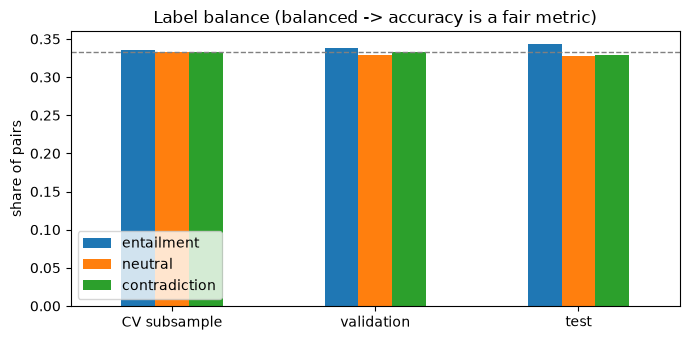

In [8]:
# chart: label balance per split
names = ["entailment", "neutral", "contradiction"]
counts = pd.DataFrame({
    "CV subsample": np.bincount(labels, minlength=3) / len(labels),
    "validation": np.bincount(val_labels, minlength=3) / len(val_labels),
    "test": np.bincount(test_df["label"], minlength=3) / len(test_df),
}, index=names)
ax = counts.T.plot.bar(figsize=(7, 3.5), rot=0)
ax.axhline(1 / 3, ls="--", c="grey", lw=1)
ax.set_ylabel("share of pairs"); ax.set_title("Label balance (balanced -> accuracy is a fair metric)")
plt.tight_layout(); plt.show()

## Representations

* **Token indicator / bag-of-words**: `train_tokenizer` (BPE) → `TokenIndicator` / `BagofWords` → `PairEncoder`. The tokenizer is retrained on the training part of every split.
* **MPNet**: `MPNetEncoder` → `PairEncoder` gives `[premise ; hypothesis]` (1536 numbers). The encoder is pretrained and frozen, so each pair is encoded once and the folds index into it.

Encodings are cached, so each one is computed once and shared by all models.

In [9]:
def fit_tokenizer(pair_list, vocab_size):
    premises = list({p for p, _ in pair_list})   # premises repeat ~3x in SNLI
    hyps = [h for _, h in pair_list]
    return train_tokenizer(premises + hyps, vocab_size, min_frequency=2)

def split_pairs(split):
    if split == "tune":
        return pairs, val_pairs
    tr, va = FOLDS[split]
    return [pairs[i] for i in tr], [pairs[i] for i in va]

_TOKS, _ENC = {}, {}

def get_X(rep, split, V=None, overlap=False):
    # (X_train, X_eval) for "tune" or CV fold `split`
    if rep == "mpnet":
        if split == "tune":
            return MPNET_SUB, MPNET_VAL
        tr, va = FOLDS[split]
        return MPNET_SUB[tr], MPNET_SUB[va]
    V, overlap = int(V), bool(overlap)
    if (split, V) not in _TOKS:
        _TOKS[(split, V)] = fit_tokenizer(split_pairs(split)[0], V)      # trained on the training part only
    key = (split, V, rep, overlap)
    if key not in _ENC:
        tok = _TOKS[(split, V)]
        enc = PairEncoder(TokenIndicator(tok) if rep == "indicator" else BagofWords(tok), overlap=overlap)
        tr_p, ev_p = split_pairs(split)
        _ENC[key] = (encode_sparse(tr_p, enc), encode_sparse(ev_p, enc))
    return _ENC[key]

In [10]:
%%time
# MPNet: MPNetEncoder + PairEncoder, one sentence per call (takes a while)
sentence_model = SentenceTransformer(ST_MODEL, device=str(DEVICE))
mpnet_pair = PairEncoder(MPNetEncoder(sentence_model))

def encode_dense(pair_list, encoder, chunk=2000):
    out = []
    for s in range(0, len(pair_list), chunk):
        out.append(np.stack([encoder(x) for x in pair_list[s:s + chunk]]).astype(np.float32))
        print(f"  {min(s + chunk, len(pair_list))}/{len(pair_list)}", end="\r")
    print()
    return np.concatenate(out)

MPNET_SUB = encode_dense(pairs, mpnet_pair)
MPNET_VAL = encode_dense(val_pairs, mpnet_pair)
print(MPNET_SUB.shape, MPNET_VAL.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  50000/50000
  9842/9842
(50000, 1536) (9842, 1536)
CPU times: user 11min 13s, sys: 1min 21s, total: 12min 34s
Wall time: 21min 25s


## Models and helpers

In [11]:
# log-linear: the model loglin.fit trains on CPU (tutorial), called on the cached matrices
def fit_loglin(X, y):
    return LogisticRegression(solver="saga", max_iter=1000, random_state=SEED).fit(X, y)


# MLPs (models.py): VectorMLPSimple / VectorMLPNLI with their default sizes
MODELS = {"mlpsimple": VectorMLPSimple, "mlpnli": VectorMLPNLI}

def dense(X):
    return X.toarray() if hasattr(X, "toarray") else X   # sparse token vectors -> dense batch

def mlp_predict(model, X):
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, X.shape[0], 2048):
            out.append(model(torch.as_tensor(dense(X[s:s + 2048]), device=DEVICE)).argmax(-1).cpu().numpy())
    return np.concatenate(out)

def mlp_epochs(name, X, y, epochs, dropout, lr, weight_decay, batch_size, clip):
    # AdamW + cross-entropy, settings from TRAIN_ARGS[name]; yields (epoch, model) after every epoch
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = MODELS[name](X.shape[1], dropout=dropout).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = torch.nn.CrossEntropyLoss()
    y_t = torch.as_tensor(y, dtype=torch.long)
    for e in range(1, epochs + 1):
        model.train()
        perm = rng.permutation(X.shape[0])
        for s in range(0, len(perm), batch_size):
            b = perm[s:s + batch_size]
            loss = loss_fn(model(torch.as_tensor(dense(X[b]), device=DEVICE)), y_t[b].to(DEVICE))
            opt.zero_grad()
            loss.backward()
            if clip:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        yield e, model


tuning, cv = [], []   # all tuning runs (validation split) and all CV results (held-out folds)

def best_setting(system):
    # highest validation accuracy (ties -> first tried: smaller vocab / no overlap / fewer epochs)
    t = pd.DataFrame(tuning)
    t = t[t.system == system]
    return t.loc[t.val_acc.idxmax()]

def run_cv(system, rep, model):
    # 5-fold CV with the system's best setting; the last epoch is reported (no best-epoch picking on the fold)
    b = best_setting(system)
    for f in range(K):
        t0 = time.time()
        Xtr, Xva = get_X(rep, f, b.vocab, b.overlap)
        ytr, yva = get_y(f)
        if model == "loglin":
            m = fit_loglin(Xtr, ytr)
            tr_acc, preds = accuracy_score(ytr, m.predict(Xtr)), m.predict(Xva)
        else:
            for _, m in mlp_epochs(model, Xtr, ytr, int(b.epochs), **TRAIN_ARGS[model]):
                pass
            tr_acc, preds = accuracy_score(ytr, mlp_predict(m, Xtr)), mlp_predict(m, Xva)
        cv.append(dict(system=system, fold=f, train_accuracy=tr_acc,
                       accuracy=accuracy_score(yva, preds), macro_f1=f1_score(yva, preds, average="macro")))
        print(f"fold {f}  {system:<16} train {tr_acc:.4f}  val {cv[-1]['accuracy']:.4f}  ({time.time() - t0:.0f}s)")

def cv_summary(systems=None):
    c = pd.DataFrame(cv)
    if systems is not None:
        c = c[c.system.isin(systems)]
    return (c.groupby("system")[["train_accuracy", "accuracy", "macro_f1"]].agg(["mean", "std"])
            .sort_values(("accuracy", "mean"), ascending=False).round(4))

def settings_for(rep, model):
    # (vocab, overlap) combinations to tune
    if rep == "mpnet":
        return [(np.nan, False)]
    overlaps = [False] if model == "mlpnli" else OVERLAPS
    return [(V, ov) for V in VOCAB_SIZES for ov in overlaps]

def tune(model):
    ytr, yva = get_y("tune")
    for rep in REPS:
        system = f"{SHORT[rep]}_{model}"
        for V, ov in settings_for(rep, model):
            t0 = time.time()
            Xtr, Xva = get_X(rep, "tune", V, ov)
            runs = [(np.nan, fit_loglin(Xtr, ytr))] if model == "loglin" else mlp_epochs(model, Xtr, ytr, MAX_EPOCHS, **TRAIN_ARGS[model])
            for e, m in runs:
                pr = (lambda X: m.predict(X)) if model == "loglin" else (lambda X: mlp_predict(m, X))
                tuning.append(dict(system=system, rep=rep, model=model, vocab=V, overlap=ov, epochs=e,
                                   train_acc=accuracy_score(ytr, pr(Xtr)), val_acc=accuracy_score(yva, pr(Xva))))
            r = pd.DataFrame(tuning[-(1 if model == "loglin" else MAX_EPOCHS):])
            r = r.loc[r.val_acc.idxmax()]
            ep = "" if model == "loglin" else f"  best epoch {int(r.epochs):>2}"
            print(f"{system:<16} vocab {V}  overlap {ov!s:<5}{ep}  train {r.train_acc:.4f}  val {r.val_acc:.4f}  ({time.time() - t0:.0f}s)")

In [12]:
# chart helpers
def plot_vocab_overlap(model):
    # validation accuracy per vocab size (best epoch for MLPs), with / without overlap
    t = pd.DataFrame(tuning)
    t = t[t.model == model]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, rep in zip(axes, ["indicator", "bow"]):
        d = t[t.rep == rep].groupby(["vocab", "overlap"]).val_acc.max().unstack()
        d.columns = ["no overlap" if not c else "with overlap" for c in d.columns]
        d.plot.bar(ax=ax, rot=0)
        mp = t[t.rep == "mpnet"].val_acc.max()
        ax.axhline(mp, ls="--", c="grey", label=f"mpnet_{model}")
        ax.set_title(f"{SHORT[rep]}_{model}"); ax.set_xlabel("BPE vocab size"); ax.set_ylabel("validation accuracy")
        ax.set_ylim(0.5, None); ax.legend(fontsize=8)
    plt.suptitle(f"{model}: tuning on the official validation split"); plt.tight_layout(); plt.show()

def plot_curves(model):
    # learning curves at each system's best vocab / overlap (solid = validation, dashed = train)
    t = pd.DataFrame(tuning)
    fig, ax = plt.subplots(figsize=(9, 4))
    for rep in REPS:
        system = f"{SHORT[rep]}_{model}"
        b = best_setting(system)
        c = t[(t.system == system) & ((t.vocab == b.vocab) | t.vocab.isna()) & (t.overlap == b.overlap)]
        line, = ax.plot(c.epochs, c.val_acc, marker="o", ms=3, label=f"{system} val")
        ax.plot(c.epochs, c.train_acc, ls="--", color=line.get_color(), label=f"{system} train")
        ax.axvline(b.epochs, color=line.get_color(), ls=":", lw=1)
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title(f"{model} learning curves (dotted = chosen epochs)")
    ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

## 1. Log-linear

Multinomial logistic regression (`saga` solver, as in `loglin.fit`). Tuned per representation: vocab size × overlap.

In [13]:
%%time
tune("loglin")




ti_loglin        vocab 1000  overlap False  train 0.6335  val 0.5985  (17s)
ti_loglin        vocab 1000  overlap True   train 0.7226  val 0.6782  (19s)



ti_loglin        vocab 5000  overlap False  train 0.7551  val 0.5968  (88s)
ti_loglin        vocab 5000  overlap True   train 0.8210  val 0.6436  (87s)



ti_loglin        vocab 10000  overlap False  train 0.8167  val 0.6018  (174s)
ti_loglin        vocab 10000  overlap True   train 0.8664  val 0.6388  (182s)
bow_loglin       vocab 1000  overlap False  train 0.6328  val 0.5953  (20s)
bow_loglin       vocab 1000  overlap True   train 0.7217  val 0.6766  (22s)
bow_loglin       vocab 5000  overlap False  train 0.7558  val 0.5971  (88s)
bow_loglin       vocab 5000  overlap True   train 0.8204  val 0.6445  (89s)
bow_loglin       vocab 10000  overlap False  train 0.8215  val 0.5994  (175s)
bow_loglin       vocab 10000  overlap True   train 0.8672  val 0.6377  (181s)
mpnet_loglin     vocab nan  overlap False  train 0.6749  val 0.6520  (2

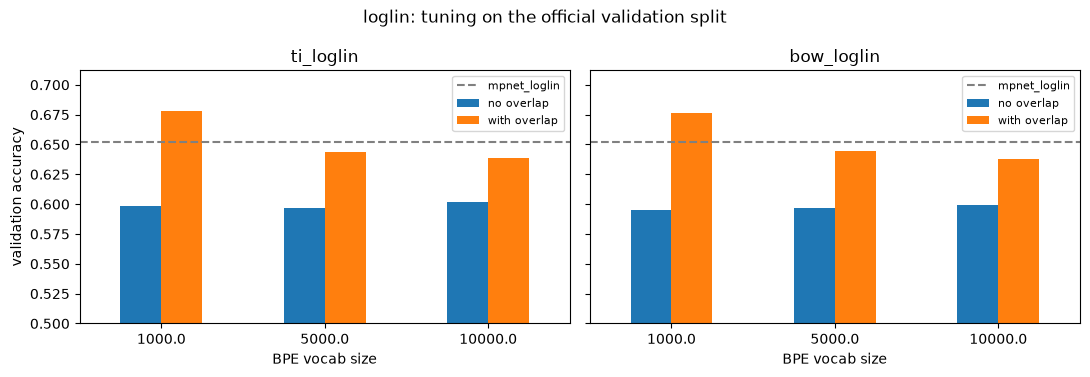

In [14]:
plot_vocab_overlap("loglin")

In [15]:
%%time
for rep in REPS:
    system = f"{SHORT[rep]}_loglin"
    print(system, "->", dict(best_setting(system)[["vocab", "overlap", "epochs"]]))
    run_cv(system, rep, "loglin")
cv_summary([f"{SHORT[r]}_loglin" for r in REPS])

ti_loglin -> {'vocab': np.float64(1000.0), 'overlap': np.True_, 'epochs': np.float64(nan)}



fold 0  ti_loglin        train 0.7275  val 0.6671  (16s)



fold 1  ti_loglin        train 0.7293  val 0.6587  (16s)



fold 2  ti_loglin        train 0.7268  val 0.6659  (16s)



fold 3  ti_loglin        train 0.7284  val 0.6629  (17s)



fold 4  ti_loglin        train 0.7288  val 0.6609  (16s)
bow_loglin -> {'vocab': np.float64(1000.0), 'overlap': np.True_, 'epochs': np.float64(nan)}
fold 0  bow_loglin       train 0.7266  val 0.6660  (17s)
fold 1  bow_loglin       train 0.7277  val 0.6589  (17s)
fold 2  bow_loglin       train 0.7258  val 0.6654  (17s)
fold 3  bow_loglin       train 0.7267  val 0.6651  (17s)
fold 4  bow_loglin       train 0.7268  val 0.6576  (17s)
mpnet_loglin -> {'vocab': np.float64(nan), 'overlap': np.False_, 'epochs': np.float64(nan)}
fold 0  mpnet_loglin     train 0.6779  val 0.6468  (23s)
fold 1  mpnet_loglin     train 0.6771  val 0.6467  (21s)
fold 2  mpnet_loglin     t

train_accuracy         accuracy         macro_f1        
                       mean     std     mean     std     mean     std
system                                                               
ti_loglin            0.7281  0.0010   0.6631  0.0035   0.6610  0.0035
bow_loglin           0.7267  0.0007   0.6626  0.0040   0.6605  0.0040
mpnet_loglin         0.6787  0.0012   0.6428  0.0042   0.6422  0.0043

## 2. MLPSimple

`VectorMLPSimple` (`models.py`): `[u ; v]` (optionally with the overlap block) → 1 hidden layer (128). The tutorial's single-hidden-layer MLP, trained with the tutorial's settings: dropout 0.1, AdamW lr 1e-4, weight decay 1e-4, batch size 64. Tuned: vocab size × overlap × epochs.

In [16]:
%%time
tune("mlpsimple")

ti_mlpsimple     vocab 1000  overlap False  best epoch 20  train 0.7184  val 0.6152  (20s)
ti_mlpsimple     vocab 1000  overlap True   best epoch 20  train 0.7737  val 0.6830  (20s)
ti_mlpsimple     vocab 5000  overlap False  best epoch  7  train 0.7323  val 0.6115  (35s)
ti_mlpsimple     vocab 5000  overlap True   best epoch  7  train 0.7860  val 0.6485  (39s)
ti_mlpsimple     vocab 10000  overlap False  best epoch  5  train 0.7540  val 0.6137  (48s)
ti_mlpsimple     vocab 10000  overlap True   best epoch  7  train 0.8240  val 0.6426  (70s)
bow_mlpsimple    vocab 1000  overlap False  best epoch 20  train 0.7233  val 0.6151  (18s)
bow_mlpsimple    vocab 1000  overlap True   best epoch 20  train 0.7766  val 0.6802  (19s)
bow_mlpsimple    vocab 5000  overlap False  best epoch  7  train 0.7319  val 0.6111  (35s)
bow_mlpsimple    vocab 5000  overlap True   best epoch  7  train 0.7845  val 0.6486  (56s)
bow_mlpsimple    vocab 10000  overlap False  best epoch  5  train 0.7532  val 0.6116  (5

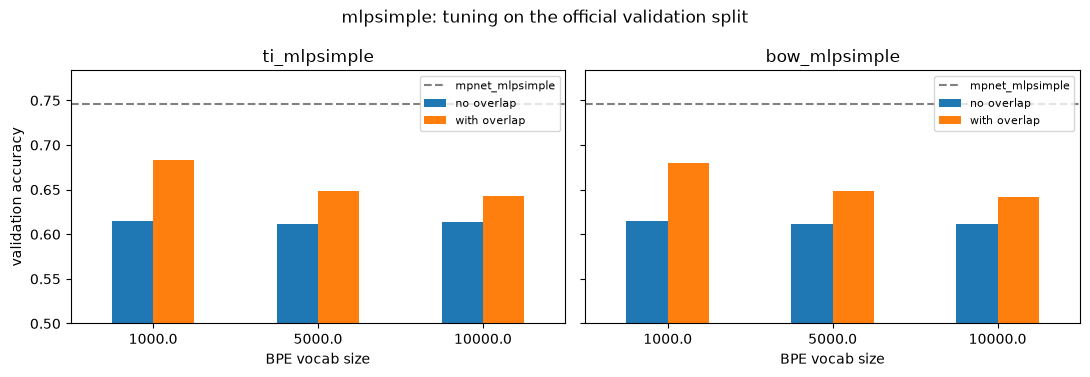

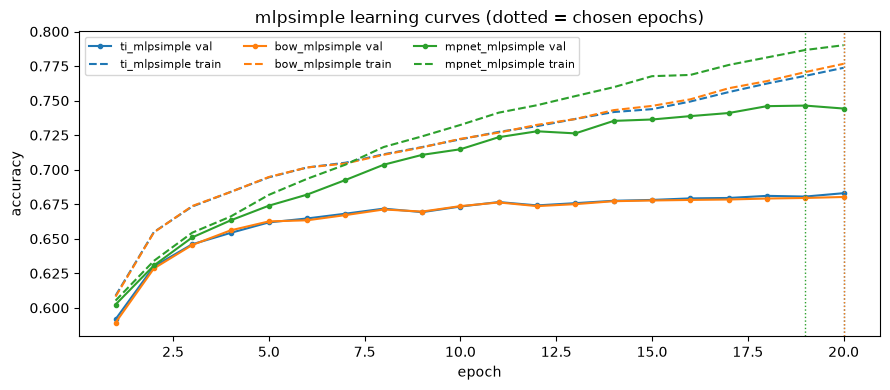

In [17]:
plot_vocab_overlap("mlpsimple")
plot_curves("mlpsimple")

In [18]:
%%time
for rep in REPS:
    system = f"{SHORT[rep]}_mlpsimple"
    print(system, "->", dict(best_setting(system)[["vocab", "overlap", "epochs"]]))
    run_cv(system, rep, "mlpsimple")
cv_summary([f"{SHORT[r]}_mlpsimple" for r in REPS])

ti_mlpsimple -> {'vocab': np.float64(1000.0), 'overlap': np.True_, 'epochs': np.float64(20.0)}
fold 0  ti_mlpsimple     train 0.7674  val 0.6688  (16s)
fold 1  ti_mlpsimple     train 0.7719  val 0.6576  (14s)
fold 2  ti_mlpsimple     train 0.7681  val 0.6706  (14s)
fold 3  ti_mlpsimple     train 0.7678  val 0.6588  (14s)
fold 4  ti_mlpsimple     train 0.7674  val 0.6630  (14s)
bow_mlpsimple -> {'vocab': np.float64(1000.0), 'overlap': np.True_, 'epochs': np.float64(20.0)}
fold 0  bow_mlpsimple    train 0.7698  val 0.6658  (14s)
fold 1  bow_mlpsimple    train 0.7696  val 0.6592  (15s)
fold 2  bow_mlpsimple    train 0.7707  val 0.6710  (15s)
fold 3  bow_mlpsimple    train 0.7671  val 0.6616  (15s)
fold 4  bow_mlpsimple    train 0.7694  val 0.6606  (15s)
mpnet_mlpsimple -> {'vocab': np.float64(nan), 'overlap': np.False_, 'epochs': np.float64(19.0)}
fold 0  mpnet_mlpsimple  train 0.7747  val 0.7294  (13s)
fold 1  mpnet_mlpsimple  train 0.7753  val 0.7303  (13s)
fold 2  mpnet_mlpsimple  trai

train_accuracy         accuracy         macro_f1        
                          mean     std     mean     std     mean     std
system                                                                  
mpnet_mlpsimple         0.7752  0.0004   0.7232  0.0061   0.7222  0.0061
ti_mlpsimple            0.7685  0.0019   0.6638  0.0058   0.6625  0.0062
bow_mlpsimple           0.7693  0.0013   0.6636  0.0048   0.6624  0.0050

## 3. MLPNLI

`VectorMLPNLI` (`models.py`): `[u, v, |u−v|, u·v]` → 2 hidden layers (128, 64). Our third model: `models.py` default dropout 0.3, optimiser as in `train_mlp.py` (AdamW lr 3e-4, weight decay 1e-6, batch size 128, gradient clipping). `u·v` already marks tokens shared by both sentences, so no overlap block. Tuned: vocab size × epochs.

In [19]:
%%time
tune("mlpnli")

ti_mlpnli        vocab 1000  overlap False  best epoch  8  train 0.8931  val 0.6850  (19s)
ti_mlpnli        vocab 5000  overlap False  best epoch  4  train 0.8596  val 0.6526  (55s)
ti_mlpnli        vocab 10000  overlap False  best epoch  3  train 0.8507  val 0.6460  (108s)
bow_mlpnli       vocab 1000  overlap False  best epoch  7  train 0.8688  val 0.6835  (18s)
bow_mlpnli       vocab 5000  overlap False  best epoch  3  train 0.8148  val 0.6531  (56s)
bow_mlpnli       vocab 10000  overlap False  best epoch  3  train 0.8494  val 0.6447  (106s)
mpnet_mlpnli     vocab nan  overlap False  best epoch 12  train 0.8596  val 0.7731  (15s)
CPU times: user 1min 8s, sys: 38.2 s, total: 1min 46s
Wall time: 6min 16s


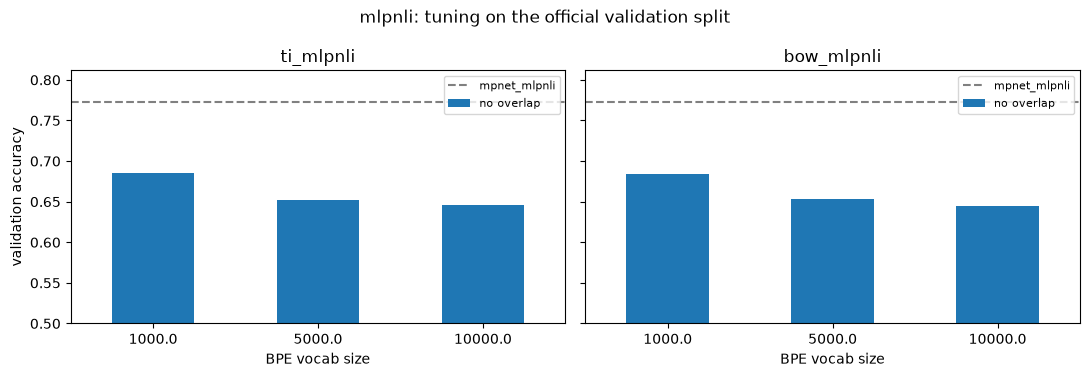

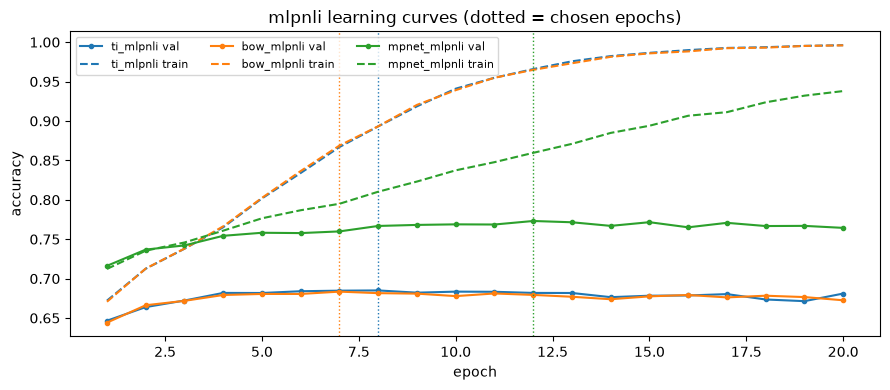

In [20]:
plot_vocab_overlap("mlpnli")
plot_curves("mlpnli")

In [21]:
%%time
for rep in REPS:
    system = f"{SHORT[rep]}_mlpnli"
    print(system, "->", dict(best_setting(system)[["vocab", "overlap", "epochs"]]))
    run_cv(system, rep, "mlpnli")
cv_summary([f"{SHORT[r]}_mlpnli" for r in REPS])

ti_mlpnli -> {'vocab': np.float64(1000.0), 'overlap': np.False_, 'epochs': np.float64(8.0)}
fold 0  ti_mlpnli        train 0.8922  val 0.6681  (19s)
fold 1  ti_mlpnli        train 0.8840  val 0.6650  (18s)
fold 2  ti_mlpnli        train 0.8931  val 0.6734  (19s)
fold 3  ti_mlpnli        train 0.8892  val 0.6655  (20s)
fold 4  ti_mlpnli        train 0.8901  val 0.6636  (19s)
bow_mlpnli -> {'vocab': np.float64(1000.0), 'overlap': np.False_, 'epochs': np.float64(7.0)}
fold 0  bow_mlpnli       train 0.8663  val 0.6709  (18s)
fold 1  bow_mlpnli       train 0.8578  val 0.6638  (18s)
fold 2  bow_mlpnli       train 0.8511  val 0.6696  (18s)
fold 3  bow_mlpnli       train 0.8560  val 0.6663  (18s)
fold 4  bow_mlpnli       train 0.8651  val 0.6617  (17s)
mpnet_mlpnli -> {'vocab': np.float64(nan), 'overlap': np.False_, 'epochs': np.float64(12.0)}
fold 0  mpnet_mlpnli     train 0.8566  val 0.7580  (7s)
fold 1  mpnet_mlpnli     train 0.8597  val 0.7571  (7s)
fold 2  mpnet_mlpnli     train 0.8494  v

train_accuracy         accuracy         macro_f1        
                       mean     std     mean     std     mean     std
system                                                               
mpnet_mlpnli         0.8557  0.0085   0.7515  0.0062   0.7499  0.0065
ti_mlpnli            0.8897  0.0036   0.6671  0.0039   0.6662  0.0040
bow_mlpnli           0.8593  0.0064   0.6665  0.0039   0.6649  0.0041

## Results: all 9 systems

In [22]:
CV = pd.DataFrame(cv)
summary = cv_summary()
ORDER = summary.index.tolist()      # best -> worst by mean CV accuracy
display(pd.DataFrame({s: best_setting(s)[["vocab", "overlap", "epochs", "val_acc"]] for s in ORDER}).T)
summary

,vocab,overlap,epochs,val_acc
mpnet_mlpnli,NaN,False,12.0,0.773115
mpnet_mlpsimple,NaN,False,19.0,0.746393
ti_mlpnli,1000.0,False,8.0,0.685023
bow_mlpnli,1000.0,False,7.0,0.683499
ti_mlpsimple,1000.0,True,20.0,0.682991
bow_mlpsimple,1000.0,True,20.0,0.680248
ti_loglin,1000.0,True,NaN,0.678216
bow_loglin,1000.0,True,NaN,0.67659
mpnet_loglin,NaN,False,NaN,0.652002


train_accuracy         accuracy         macro_f1        
                          mean     std     mean     std     mean     std
system                                                                  
mpnet_mlpnli            0.8557  0.0085   0.7515  0.0062   0.7499  0.0065
mpnet_mlpsimple         0.7752  0.0004   0.7232  0.0061   0.7222  0.0061
ti_mlpnli               0.8897  0.0036   0.6671  0.0039   0.6662  0.0040
bow_mlpnli              0.8593  0.0064   0.6665  0.0039   0.6649  0.0041
ti_mlpsimple            0.7685  0.0019   0.6638  0.0058   0.6625  0.0062
bow_mlpsimple           0.7693  0.0013   0.6636  0.0048   0.6624  0.0050
ti_loglin               0.7281  0.0010   0.6631  0.0035   0.6610  0.0035
bow_loglin              0.7267  0.0007   0.6626  0.0040   0.6605  0.0040
mpnet_loglin            0.6787  0.0012   0.6428  0.0042   0.6422  0.0043

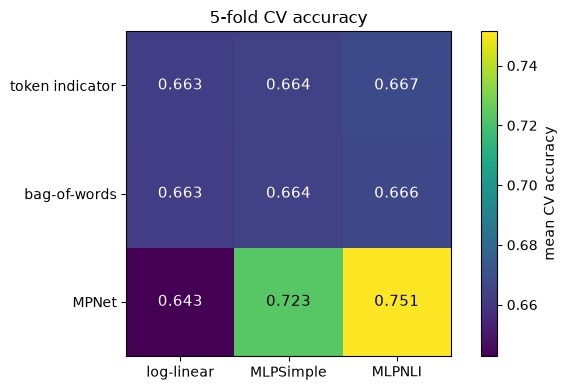

In [23]:
# chart: 3x3 grid of mean CV accuracy
grid = CV.groupby("system").accuracy.mean()
M = np.array([[grid[f"{SHORT[r]}_{m}"] for m in ["loglin", "mlpsimple", "mlpnli"]] for r in REPS])
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(M, cmap="viridis")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", color="white" if M[i, j] < M.mean() else "black", fontsize=11)
ax.set_xticks(range(3), ["log-linear", "MLPSimple", "MLPNLI"]); ax.set_yticks(range(3), ["token indicator", "bag-of-words", "MPNet"])
plt.colorbar(im, label="mean CV accuracy"); ax.set_title("5-fold CV accuracy"); plt.tight_layout(); plt.show()

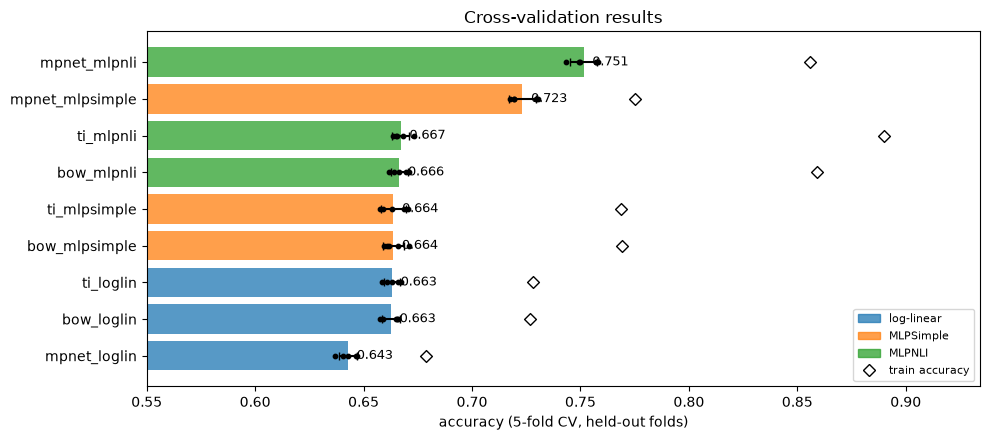

In [24]:
# chart: all systems (bar = mean +- std over folds, dots = folds, diamond = train accuracy)
colors = {"loglin": "tab:blue", "mlpsimple": "tab:orange", "mlpnli": "tab:green"}
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(ORDER))[::-1]
for yi, s in zip(y, ORDER):
    d = CV[CV.system == s]
    ax.barh(yi, d.accuracy.mean(), xerr=d.accuracy.std(), color=colors[s.split("_")[1]], alpha=0.75, capsize=3)
    ax.scatter(d.accuracy, np.full(len(d), yi), color="k", s=10, zorder=3)
    ax.scatter(d.train_accuracy.mean(), yi, marker="D", color="white", edgecolor="k", zorder=3)
    ax.text(d.accuracy.mean() + 0.004, yi, f"{d.accuracy.mean():.3f}", va="center", fontsize=9)
ax.set_yticks(y, ORDER); ax.set_xlim(0.55, None); ax.set_xlabel("accuracy (5-fold CV, held-out folds)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.75) for c in colors.values()] + \
          [plt.Line2D([], [], marker="D", ls="", markerfacecolor="white", markeredgecolor="k")]
ax.legend(handles, ["log-linear", "MLPSimple", "MLPNLI", "train accuracy"], loc="lower right", fontsize=8)
ax.set_title("Cross-validation results"); plt.tight_layout(); plt.show()

## ROPE comparison

Bayesian correlated t-test on the per-fold accuracies (`BenavoliCorrelatedT`, `eval.py`). For every pair: probability that A is better, that they are practically equivalent (difference within ±ROPE), or that B is better.

In [25]:
ACCS = {s: CV[CV.system == s].sort_values("fold")["accuracy"].to_numpy() for s in ORDER}
bct = BenavoliCorrelatedT([ACCS[s] for s in ORDER], system_names=ORDER)
p_a, p_tie, p_b = bct.probs(ROPE)

pair_names = [(ORDER[i], ORDER[j]) for i in range(len(ORDER)) for j in range(i + 1, len(ORDER))]
ROPE_TABLE = pd.DataFrame(dict(A=[a for a, _ in pair_names], B=[b for _, b in pair_names],
                               mean_diff_B_minus_A=np.ravel(bct.mean_diffs),
                               P_A_wins=np.ravel(p_a), P_tie=np.ravel(p_tie), P_B_wins=np.ravel(p_b)))
print(f"ROPE = ±{ROPE}   |   average fold-to-fold std: {CV.groupby('system')['accuracy'].std().mean():.4f}")
ROPE_TABLE.round(3)

ROPE = ±0.01   |   average fold-to-fold std: 0.0047


,A,B,mean_diff_B_minus_A,P_A_wins,P_tie,P_B_wins
0,mpnet_mlpnli,mpnet_mlpsimple,-0.028,0.999,0.001,0.000
1,mpnet_mlpnli,ti_mlpnli,-0.084,1.000,0.000,0.000
2,mpnet_mlpnli,bow_mlpnli,-0.085,1.000,0.000,0.000
3,mpnet_mlpnli,ti_mlpsimple,-0.088,1.000,0.000,0.000
4,mpnet_mlpnli,bow_mlpsimple,-0.088,1.000,0.000,0.000
5,mpnet_mlpnli,ti_loglin,-0.088,1.000,0.000,0.000
6,mpnet_mlpnli,bow_loglin,-0.089,1.000,0.000,0.000
7,mpnet_mlpnli,mpnet_loglin,-0.109,1.000,0.000,0.000
8,mpnet_mlpsimple,ti_mlpnli,-0.056,0.999,0.000,0.000
9,mpnet_mlpsimple,bow_mlpnli,-0.057,1.000,0.000,0.000


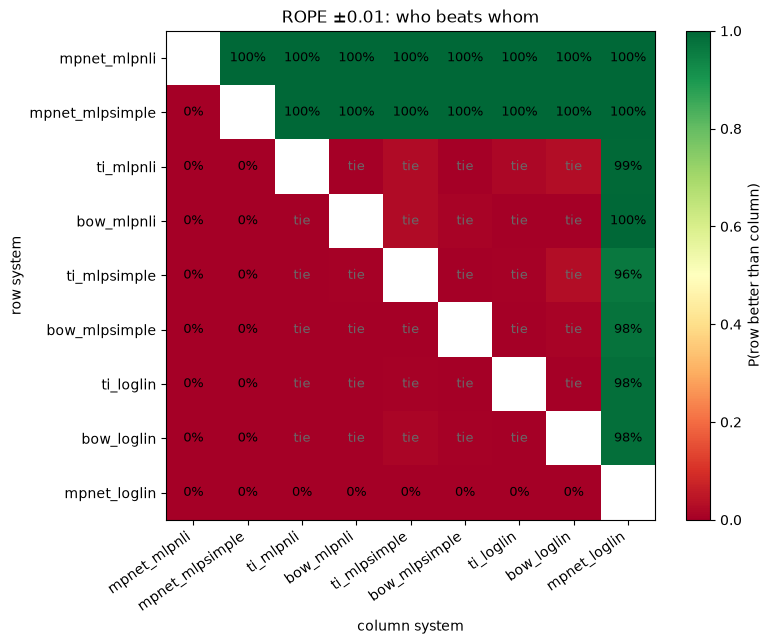

In [26]:
# chart: P(row system better than column system); "tie" = practically equivalent (P(tie) > 0.5)
n = len(ORDER)
P, T = np.full((n, n), np.nan), np.full((n, n), np.nan)
for (a, b), pa, pt, pb in zip(pair_names, np.ravel(p_a), np.ravel(p_tie), np.ravel(p_b)):
    i, j = ORDER.index(a), ORDER.index(b)
    P[i, j], P[j, i] = pa, pb
    T[i, j] = T[j, i] = pt
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(P, cmap="RdYlGn", vmin=0, vmax=1)
for i in range(n):
    for j in range(n):
        if i != j:
            tie = T[i, j] > 0.5
            ax.text(j, i, "tie" if tie else f"{P[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="dimgrey" if tie else "black")
ax.set_xticks(range(n), ORDER, rotation=35, ha="right"); ax.set_yticks(range(n), ORDER)
ax.set_xlabel("column system"); ax.set_ylabel("row system")
plt.colorbar(im, label="P(row better than column)")
ax.set_title(f"ROPE ±{ROPE}: who beats whom"); plt.tight_layout(); plt.show()

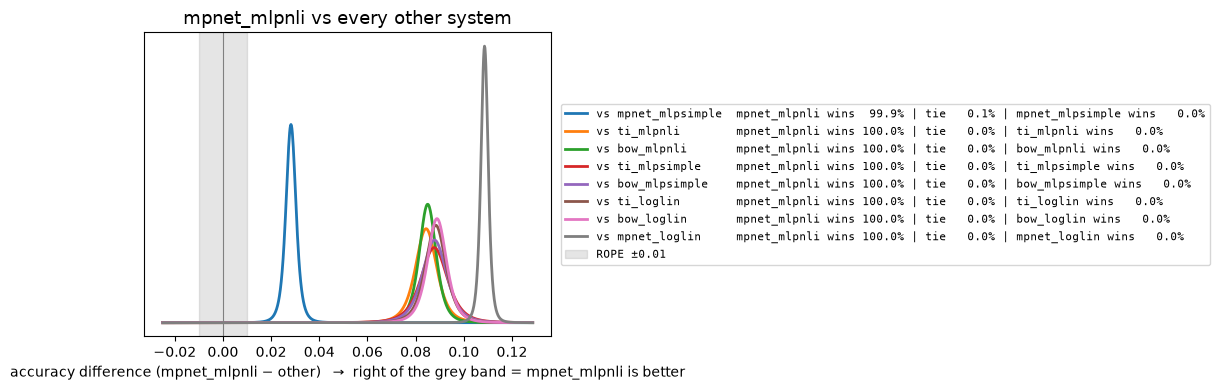

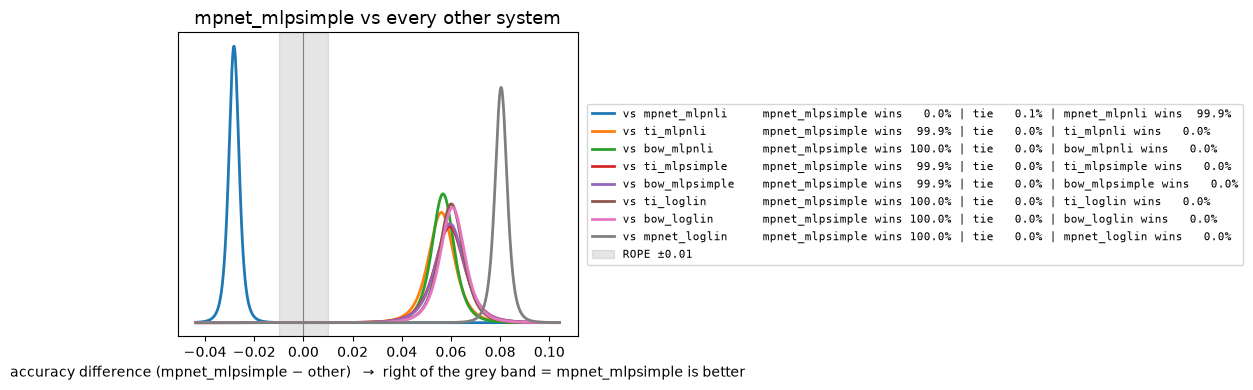

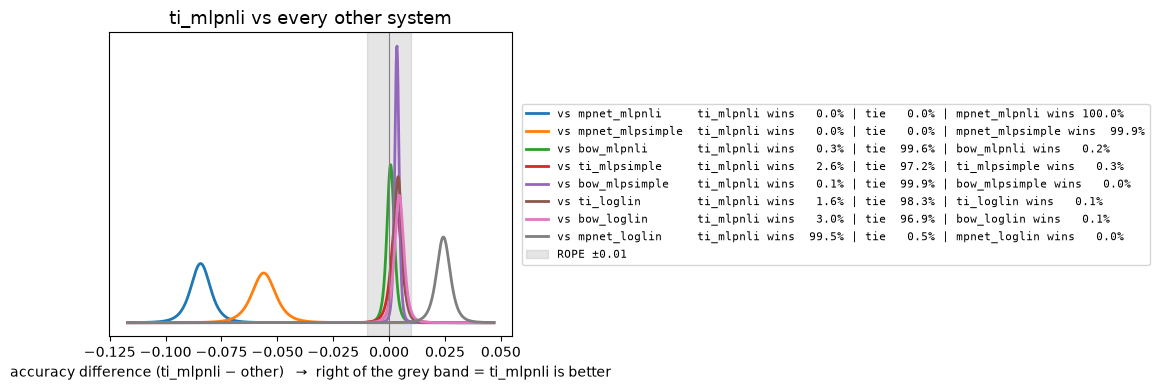

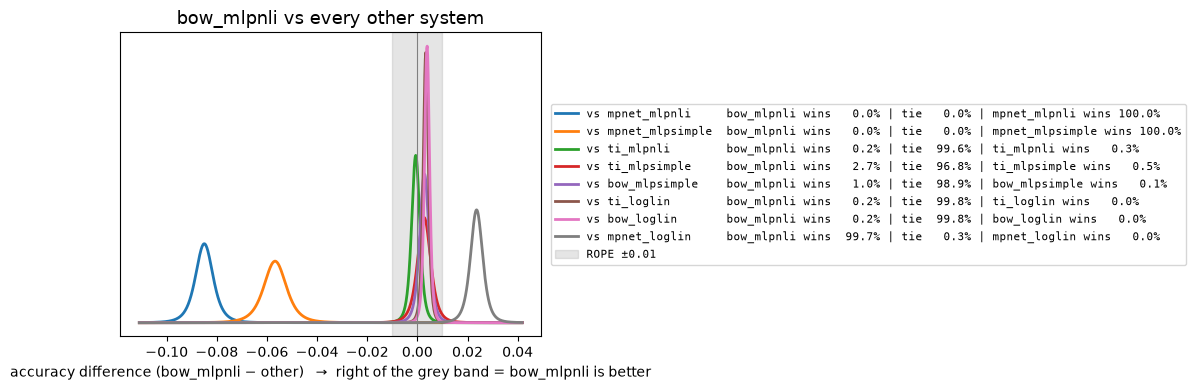

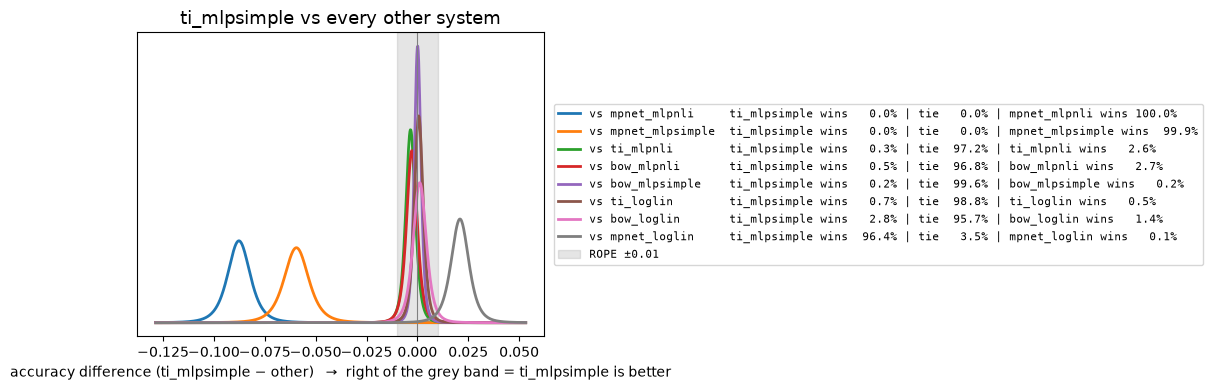

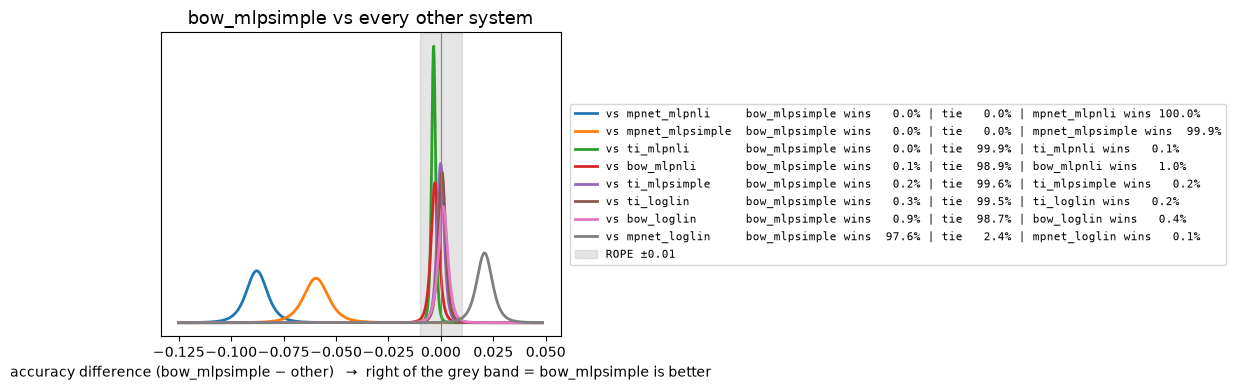

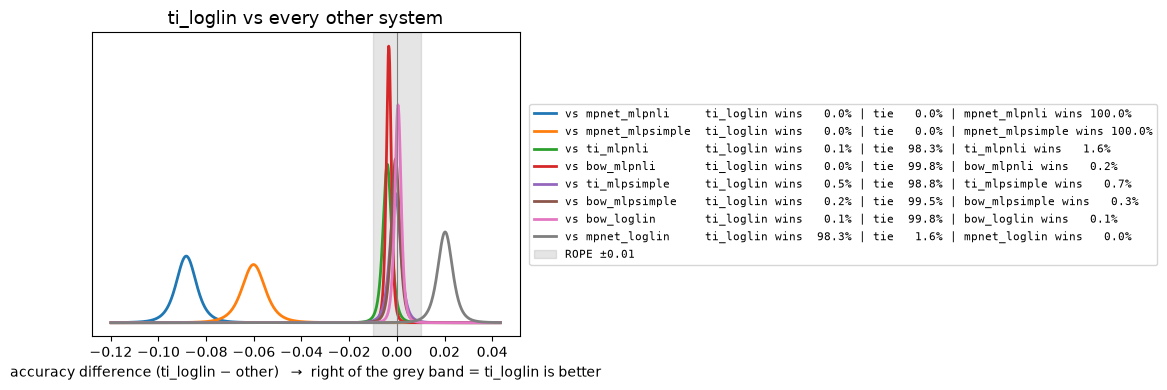

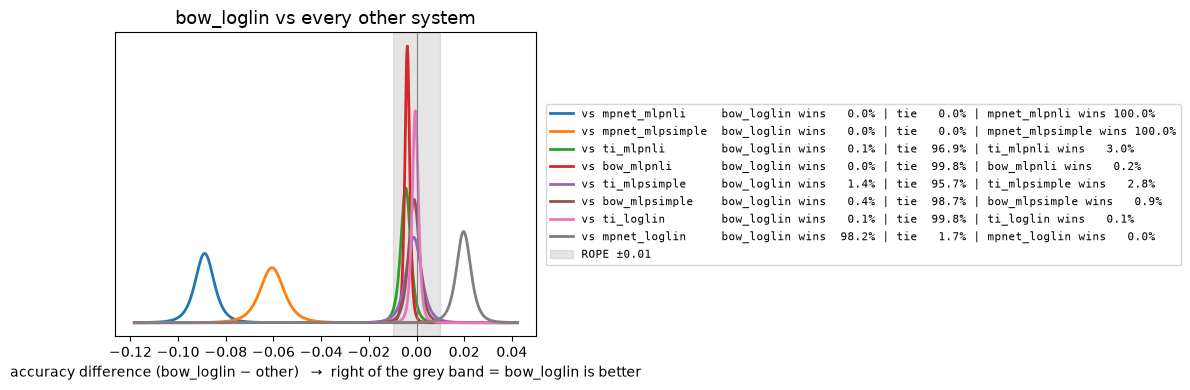

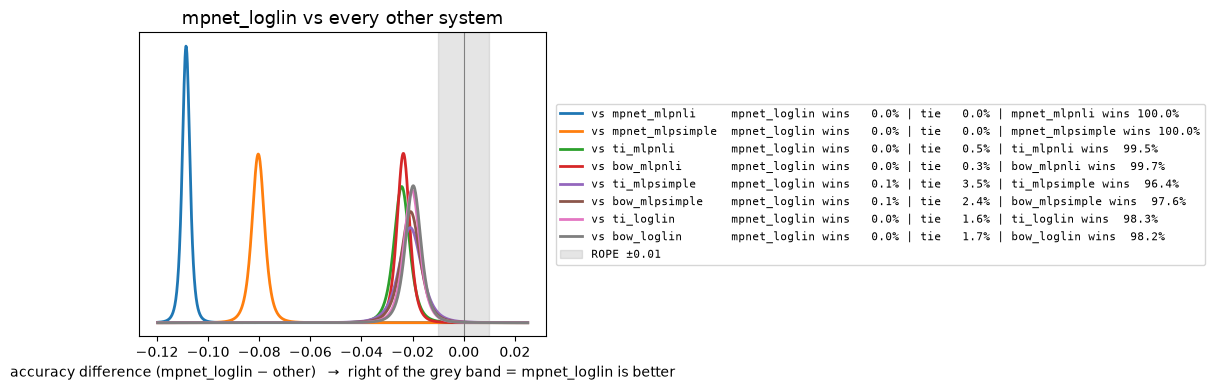

In [27]:
# chart: each system vs every other system (posterior of the accuracy difference, ROPE shaded)
for A in ORDER:
    fig, ax = plt.subplots(figsize=(11, 4))
    curves = []
    for B in ORDER:
        if B == A:
            continue
        p = BenavoliCorrelatedT([ACCS[A], ACCS[B]], system_names=[A, B])
        pa, pt, pb = [float(np.ravel(v)[0]) for v in p.probs(ROPE)]
        curves.append((B, st.t(df=p.dfs[0], loc=-p.mean_diffs[0], scale=p.stds[0]), pa, pt, pb))   # flipped: A - B
    lo = min(min(t.ppf(0.001) for _, t, *_ in curves), -2.5 * ROPE)
    hi = max(max(t.ppf(0.999) for _, t, *_ in curves), 2.5 * ROPE)
    x = np.linspace(lo, hi, 800)
    for B, t, pa, pt, pb in curves:
        ax.plot(x, t.pdf(x), lw=2, label=f"vs {B:<16} {A} wins {pa:6.1%} | tie {pt:6.1%} | {B} wins {pb:6.1%}")
    ax.axvspan(-ROPE, ROPE, color="grey", alpha=0.2, label=f"ROPE ±{ROPE}")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{A} vs every other system", fontsize=13)
    ax.set_xlabel(f"accuracy difference ({A} − other)   →  right of the grey band = {A} is better")
    ax.set_yticks([])
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), prop={"family": "monospace", "size": 8})
    plt.tight_layout(); plt.show()

## Best system: full training split + test (once)

The best system by mean CV accuracy is retrained on the full training split (~550k pairs). For MLPs the epoch is picked on the official validation split; the test split is scored at that epoch and only reported.

For MPNet on 550k pairs, one sentence per call would take hours, so the same `sentence_model` (the one inside `MPNetEncoder`) encodes 256 sentences per call; the check below confirms it gives the same vectors as `MPNetEncoder`.

best system by CV: mpnet_mlpnli | setting: {'vocab': np.float64(nan), 'overlap': np.False_, 'epochs': np.float64(12.0)}


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/2146 [00:00<?, ?it/s]

Batches:   0%|          | 0/2146 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

full training split: (549367, 1536)
epoch  1  val 0.7822
epoch  2  val 0.8005
epoch  3  val 0.8078
epoch  4  val 0.8099
epoch  5  val 0.8141
epoch  6  val 0.8217
epoch  7  val 0.8224
epoch  8  val 0.8203
epoch  9  val 0.8251
epoch 10  val 0.8279
epoch 11  val 0.8269
epoch 12  val 0.8248
epoch 13  val 0.8258
epoch 14  val 0.8264
epoch 15  val 0.8302
epoch 16  val 0.8235
epoch 17  val 0.8235
epoch 18  val 0.8262
epoch 19  val 0.8270
epoch 20  val 0.8260


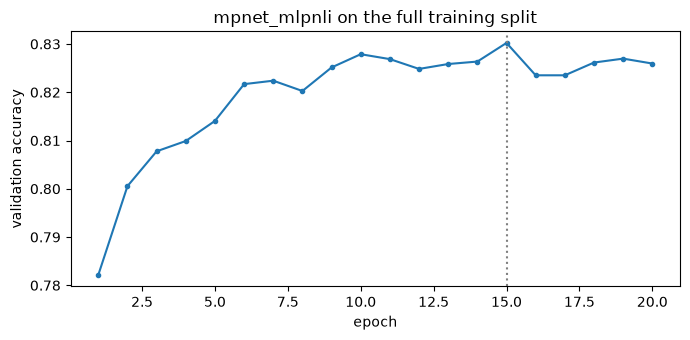


mpnet_mlpnli (full training split): {'epoch': 15, 'val': 0.8302, 'test': 0.8259, 'train': 0.868}
CPU times: user 3min 17s, sys: 1min 4s, total: 4min 22s
Wall time: 24min 36s


In [28]:
%%time
BEST_SYSTEM = ORDER[0]
b = best_setting(BEST_SYSTEM)
rep = {v: k for k, v in SHORT.items()}[BEST_SYSTEM.split("_")[0]]
model = BEST_SYSTEM.split("_")[1]
print("best system by CV:", BEST_SYSTEM, "| setting:", dict(b[["vocab", "overlap", "epochs"]]))

full_pairs = list(zip(train_df["premise"], train_df["hypothesis"]))
full_labels = train_df["label"].to_numpy()
test_pairs = list(zip(test_df["premise"], test_df["hypothesis"]))
test_labels = test_df["label"].to_numpy()

if rep == "mpnet":
    def mpnet_batched(pair_list):
        u = sentence_model.encode([p for p, _ in pair_list], batch_size=256, convert_to_numpy=True, show_progress_bar=True)
        v = sentence_model.encode([h for _, h in pair_list], batch_size=256, convert_to_numpy=True, show_progress_bar=True)
        return np.concatenate([u, v], axis=1).astype(np.float32)
    assert np.allclose(mpnet_batched(pairs[:50]), MPNET_SUB[:50], atol=1e-3), "batched encoding != MPNetEncoder"
    Xfull, Xval, Xtest = mpnet_batched(full_pairs), MPNET_VAL, mpnet_batched(test_pairs)
else:
    tok = fit_tokenizer(full_pairs, int(b.vocab))
    enc = PairEncoder(TokenIndicator(tok) if rep == "indicator" else BagofWords(tok), overlap=bool(b.overlap))
    Xfull, Xval, Xtest = encode_sparse(full_pairs, enc), encode_sparse(val_pairs, enc), encode_sparse(test_pairs, enc)
print("full training split:", Xfull.shape)

if model == "loglin":
    m = fit_loglin(Xfull, full_labels)
    final = dict(train=accuracy_score(full_labels, m.predict(Xfull)),
                 val=accuracy_score(val_labels, m.predict(Xval)), test=accuracy_score(test_labels, m.predict(Xtest)))
else:
    curve, final = [], dict(val=-1.0)
    for e, m in mlp_epochs(model, Xfull, full_labels, MAX_EPOCHS, **TRAIN_ARGS[model]):
        va = accuracy_score(val_labels, mlp_predict(m, Xval))
        curve.append(va)
        print(f"epoch {e:>2}  val {va:.4f}")
        if va > final["val"]:
            final = dict(epoch=e, val=va, test=accuracy_score(test_labels, mlp_predict(m, Xtest)),
                         train=accuracy_score(full_labels, mlp_predict(m, Xfull)))
    plt.figure(figsize=(7, 3.5)); plt.plot(range(1, len(curve) + 1), curve, marker="o", ms=3)
    plt.axvline(final["epoch"], ls=":", c="grey"); plt.xlabel("epoch"); plt.ylabel("validation accuracy")
    plt.title(f"{BEST_SYSTEM} on the full training split"); plt.tight_layout(); plt.show()

print(f"\n{BEST_SYSTEM} (full training split):", {k: round(v, 4) if isinstance(v, float) else v for k, v in final.items()})